# Study 23 - Revised figures for the ESE resubmission

Regenerates the data figures with the problems found in the submitted version fixed. Nothing in the earlier notebooks is changed.

- Figures 5 and 6 are recomputed with the **specified four-signal estimator** (PM2.5, wind, boundary layer height, temperature). The submitted versions came from a three-signal run.
- Figures 3, 4, 7 and the new-station, Beijing and sensitivity figures are redrawn from the CSV files already produced by studies 5, 12, 14, 17, 18 and 21.
- One colour-blind-safe palette, one naming ('estimator'), panel letters, ticks at the data points, units as ug m-3.
- Each figure is saved as PNG (300 dpi) and vector PDF in `../outputs/study23_figures/`.


In [1]:
import numpy as np, pandas as pd, math, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingClassifier
np.random.seed(0)
OUT=Path("../outputs/study23_figures"); OUT.mkdir(parents=True,exist_ok=True); O=Path("../outputs")
plt.rcParams.update({"figure.dpi":120,"savefig.dpi":300,"font.size":9,"axes.labelsize":9,"legend.fontsize":8,"xtick.labelsize":8,"ytick.labelsize":8,
    "axes.grid":True,"grid.alpha":0.25,"axes.spines.top":False,"axes.spines.right":False,"pdf.fonttype":42,"savefig.facecolor":"white"})
BLUE,ORANGE,GREEN,VERM,PURPLE,GREY="#0072B2","#E69F00","#009E73","#D55E00","#CC79A7","#777777"   # Okabe-Ito
W2=6.69   # 170 mm
UG=r"$\mu$g m$^{-3}$"
def letter(ax,s,x=-0.14,y=1.04): ax.text(x,y,s,transform=ax.transAxes,fontweight="bold",fontsize=11,va="bottom")
def save(fig,name):
    fig.savefig(OUT/f"{name}.png",bbox_inches="tight"); fig.savefig(OUT/f"{name}.pdf",bbox_inches="tight"); plt.show(); print("saved",name)


/Users/sumiyasayeed/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
/Users/sumiyasayeed/anaconda3/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


## Figure 3 - marginalising against forward-filling (from study12 CSV)


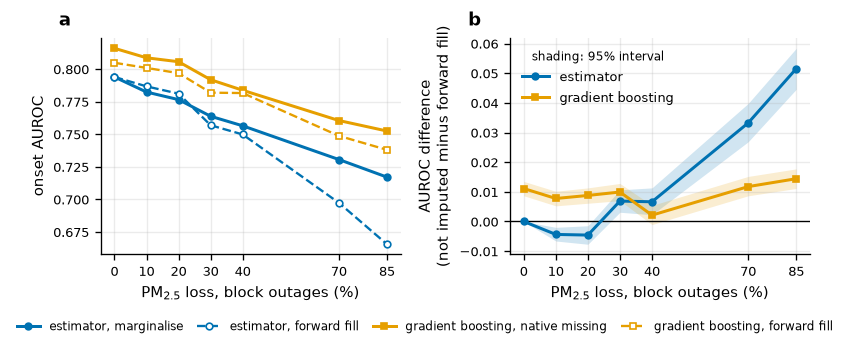

saved fig3_mechanism
NOTE for the caption: at 0% loss the gradient boosting difference is 0.011, not 0, because the two gradient boosting models are trained separately


In [2]:
M=pd.read_csv(O/"study12_block_outage/b3_mechanism_marginalise_vs_impute.csv"); x=M.loss*100
fig,ax=plt.subplots(1,2,figsize=(W2,2.7))
ax[0].plot(x,M.pemdt_marg,"-o",color=BLUE,lw=1.8,ms=4,label="estimator, marginalise")
ax[0].plot(x,M.pemdt_ff,"--o",color=BLUE,lw=1.4,ms=4,mfc="white",label="estimator, forward fill")
ax[0].plot(x,M.gbm_marg,"-s",color=ORANGE,lw=1.8,ms=4,label="gradient boosting, native missing")
ax[0].plot(x,M.gbm_ff,"--s",color=ORANGE,lw=1.4,ms=4,mfc="white",label="gradient boosting, forward fill")
ax[0].set_ylabel("onset AUROC"); h_,l_=ax[0].get_legend_handles_labels(); fig.legend(h_,l_,frameon=False,loc="lower center",ncol=4,bbox_to_anchor=(0.5,-0.08),fontsize=7,columnspacing=1.2)
ax[1].axhline(0,color="k",lw=.8)
for d,lo,hi,c,m,lab in [(M.pemdt_diff,M.pemdt_lo,M.pemdt_hi,BLUE,"o","estimator"),(M.gbm_diff,M.gbm_lo,M.gbm_hi,ORANGE,"s","gradient boosting")]:
    ax[1].fill_between(x,lo,hi,color=c,alpha=.18,lw=0); ax[1].plot(x,d,"-"+m,color=c,lw=1.8,ms=4,label=lab)
ax[1].set_ylabel("AUROC difference\n(not imputed minus forward fill)"); ax[1].legend(frameon=False,loc="upper left",title="shading: 95% interval",title_fontsize=7)
for a,s in zip(ax,"ab"):
    a.set_xticks(list(x)); a.set_xlabel(r"PM$_{2.5}$ loss, block outages (%)"); letter(a,s)
plt.tight_layout(); save(fig,"fig3_mechanism")
print("NOTE for the caption: at 0%% loss the gradient boosting difference is %.3f, not 0, because the two gradient boosting models are trained separately"%M.gbm_diff.iloc[0])


## Figure 4 - advantage by threshold (from study12 CSV)


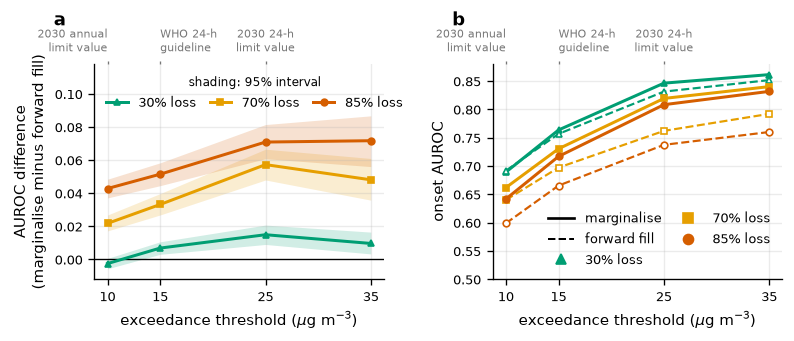

saved fig4_mechanism_by_threshold


In [3]:
T=pd.read_csv(O/"study12_block_outage/b3_mechanism_by_threshold.csv"); T=T[T.loss>0]
cols={0.30:GREEN,0.70:ORANGE,0.85:VERM}; mk={0.30:"^",0.70:"s",0.85:"o"}
fig,ax=plt.subplots(1,2,figsize=(W2,3.0))
ax[0].axhline(0,color="k",lw=.8)
for p,g in T.groupby("loss"):
    g=g.sort_values("tau"); ax[0].fill_between(g.tau,g.lo95,g.hi95,color=cols[p],alpha=.18,lw=0)
    ax[0].plot(g.tau,g["diff"],"-"+mk[p],color=cols[p],lw=1.8,ms=4,label=f"{p:.0%} loss")
    ax[1].plot(g.tau,g.pemdt_marg,"-"+mk[p],color=cols[p],lw=1.8,ms=4)
    ax[1].plot(g.tau,g.pemdt_ff,"--"+mk[p],color=cols[p],lw=1.3,ms=4,mfc="white")
ax[0].set_ylabel("AUROC difference\n(marginalise minus forward fill)"); ax[0].set_ylim(-0.012,0.118); ax[0].legend(frameon=False,loc="upper left",ncol=3,columnspacing=1.0,handlelength=1.6,title="shading: 95% interval",title_fontsize=7)
ax[1].set_ylabel("onset AUROC")
ax[1].plot([],[],"-",color="k",lw=1.6,label="marginalise"); ax[1].plot([],[],"--",color="k",lw=1.2,label="forward fill")
for p in cols: ax[1].plot([],[],mk[p],color=cols[p],label=f"{p:.0%} loss")
ax[1].set_ylim(0.50,0.88); ax[1].legend(frameon=False,loc="lower right",ncol=2,columnspacing=1.0)
for a,s in zip(ax,"ab"):
    a.set_xticks([10,15,25,35]); a.set_xlabel(f"exceedance threshold ({UG})"); letter(a,s,y=1.16)
    top=a.secondary_xaxis("top"); top.set_xticks([10,15,25]); top.set_xticklabels(["2030 annual\nlimit value","WHO 24-h\nguideline","2030 24-h\nlimit value"],fontsize=6.5,color=GREY)
    top.tick_params(length=2,color=GREY); top.spines["top"].set_visible(False)
    for lab_,ha_ in zip(top.get_xticklabels(),["right","left","center"]): lab_.set_ha(ha_)
plt.tight_layout(); save(fig,"fig4_mechanism_by_threshold")


## Recompute with the specified four-signal estimator (for Figures 5, 6 and the case study)


In [4]:
STEP=6; H=4; TAU=15.0
pm=pd.read_csv("../data/openaq_regional/regional_pm25.csv"); pm["datetime"]=pd.to_datetime(pm["datetime"],utc=True)
pm["name"]=pm.station.str.split("::").str[1]; pm=pm.dropna(subset=["value"]); pm=pm[(pm.value>=0)&(pm.value<1500)]
met=pd.read_csv("../data/era5/era5_regional.csv",usecols=["datetime","station","wind_speed","blh","t2m"]); met["datetime"]=pd.to_datetime(met["datetime"],utc=True)
yrs=pm.groupby("station")["datetime"].agg(lambda s:(s.max()-s.min()).days/365.25); pm=pm[pm.station.isin(yrs[yrs>=2].index)].copy()
K=5; LEV=[i/(K-1) for i in range(K)]; SDL=[1.0+0.5*l for l in LEV]; LOGC=0.5*math.log(2*math.pi); LGC=[-LOGC-math.log(sd) for sd in SDL]
def lgv(z): return [LGC[k]-0.5*((z-2.0*LEV[k])/SDL[k])**2 for k in range(K)]
SIG=[("pm",1.0,1),("wind",0.5,-1),("blh",0.5,-1),("temp",0.4,-1)]        # specified weights and orientations
def twin_llr(Z):
    """Four-signal estimator. Z: dict of z-score arrays. Returns risk and the per-signal contribution phi (Eq. attribution)."""
    n=len(Z["pm"]); logb=[-3*k for k in range(K)]; m=max(logb); ss=sum(math.exp(x-m) for x in logb); logb=[x-m-math.log(ss) for x in logb]
    risk=np.empty(n); PHI={s:np.zeros(n) for s,_,_ in SIG}
    for t in range(n):
        mb=max(logb); b=[math.exp(x-mb) for x in logb]; sb=sum(b); b=[x/sb for x in b]
        el=sum(b[k]*LEV[k] for k in range(K)); up=0.25; pdn=0.05 if el>0.4 else 0.15; bp=[0.0]*K
        for k in range(K):
            u=up if k<K-1 else 0.0; d=pdn if k>0 else 0.0; bp[k]+=b[k]*(1-u-d)
            if k<K-1: bp[k+1]+=b[k]*u
            if k>0: bp[k-1]+=b[k]*d
        logbp=[math.log(x+1e-12) for x in bp]
        for s,w,o in SIG:
            zv=Z[s][t]
            if not math.isnan(zv):
                lv=lgv(o*zv); logbp=[logbp[k]+w*lv[k] for k in range(K)]; PHI[s][t]=w*(lv[K-1]-lv[0])
        m2=max(logbp); s2=math.log(sum(math.exp(x-m2) for x in logbp)); logb=[x-m2-s2 for x in logbp]
        risk[t]=sum(math.exp(logb[k])*LEV[k] for k in range(K))
    return risk,PHI
def auc(s,y):
    s=np.asarray(s,float);y=np.asarray(y,int);pos,neg=(y==1),(y==0)
    o=np.argsort(s);r=np.empty(len(s));r[o]=np.arange(1,len(s)+1)
    u,inv,c=np.unique(s,return_inverse=True,return_counts=True);sm=np.zeros(len(c));np.add.at(sm,inv,r);r=(sm/c)[inv]
    return float((r[pos].sum()-pos.sum()*(pos.sum()+1)/2)/(pos.sum()*neg.sum()))
def brier(p,y): return float(np.mean((np.asarray(p,float)-np.asarray(y,float))**2))
def ece(p,y,nb=10):
    p=np.asarray(p,float); y=np.asarray(y,float); ed=np.linspace(0,1,nb+1); e=0.0
    for i in range(nb):
        mk_=(p>=ed[i])&(p<ed[i+1] if i<nb-1 else p<=ed[i+1])
        if mk_.sum(): e+=mk_.mean()*abs(y[mk_].mean()-p[mk_].mean())
    return float(e)
def platt_fit(x,y,ep=3000,lr=.3):
    x=np.asarray(x,float);mu,sd=x.mean(),x.std()+1e-9;xs=(x-mu)/sd;w=0.;bi=0.
    for _ in range(ep): p=1/(1+np.exp(-(w*xs+bi)));w-=lr*np.mean((p-y)*xs);bi-=lr*np.mean(p-y)
    return lambda z:1/(1+np.exp(-(w*((np.asarray(z,float)-mu)/sd)+bi)))
FEATS=["zpm","zpm_l1","zpm_l2","zpm_tr","zwind","zblh","ztemp","hour_sin","hour_cos","doy_sin","doy_cos"]
g2=lambda a:(a if not np.isnan(a) else 0.0); ST={}; rows=[]
for st,g in pm.groupby("station"):
    s=g.set_index("datetime").value.resample(f"{STEP}h").mean()
    mg=met[met.station==g["name"].iloc[0]].set_index("datetime")[["wind_speed","blh","t2m"]].resample(f"{STEP}h").mean()
    idx=s.index; A=pd.DataFrame({"pm":s}).join(mg).reindex(idx); tm=(idx.month%2==0)
    def z(col,log=False):
        v=np.log1p(np.clip(A[col].to_numpy(),0,None)) if log else A[col].to_numpy()
        return (v-np.nanmean(v[tm]))/(np.nanstd(v[tm])+1e-9)
    Z=dict(pm=z("pm",True),wind=z("wind_speed"),blh=z("blh"),temp=z("t2m")); risk,PHI=twin_llr(Z)
    v=A["pm"].to_numpy(); hr=idx.hour.to_numpy(); doy=idx.dayofyear.to_numpy(); ST[st]=dict(v=v,risk=risk,PHI=PHI,idx=idx,tm=tm)
    for t in range(2,len(v)-H):
        if np.isnan(v[t]) or v[t]>=TAU: continue
        fut=v[t+1:t+1+H]
        if np.all(np.isnan(fut)): continue
        zp=Z["pm"]
        rows.append(dict(split="train" if tm[t] else "test",label=int(np.nanmax(fut)>=TAU),risk=risk[t],
            zpm=g2(zp[t]),zpm_l1=g2(zp[t-1]),zpm_l2=g2(zp[t-2]),zpm_tr=g2(zp[t]-zp[t-2]),zwind=g2(Z["wind"][t]),zblh=g2(Z["blh"][t]),ztemp=g2(Z["temp"][t]),
            hour_sin=math.sin(2*math.pi*hr[t]/24),hour_cos=math.cos(2*math.pi*hr[t]/24),doy_sin=math.sin(2*math.pi*doy[t]/365),doy_cos=math.cos(2*math.pi*doy[t]/365),
            **{f"phi_{s}":PHI[s][t] for s,_,_ in SIG}))
S=pd.DataFrame(rows); tr,te=S[S.split=="train"],S[S.split=="test"]; ytr,yte=tr.label.values,te.label.values
p_raw=te.risk.values; p_cal=platt_fit(tr.risk.values,ytr)(p_raw)
p_gbm=HistGradientBoostingClassifier(max_iter=300,learning_rate=0.05,max_depth=4,l2_regularization=1.0,random_state=0).fit(tr[FEATS].values,ytr).predict_proba(te[FEATS].values)[:,1]
NUM=pd.DataFrame([dict(quantity="estimator AUROC (check: 0.794)",value=auc(p_raw,yte)),dict(quantity="test base rate",value=yte.mean()),
    dict(quantity="mean raw risk at prediction points",value=p_raw.mean()),dict(quantity="Brier, raw risk",value=brier(p_raw,yte)),
    dict(quantity="Brier, recalibrated estimator",value=brier(p_cal,yte)),dict(quantity="ECE, recalibrated estimator",value=ece(p_cal,yte)),
    dict(quantity="Brier, gradient boosting",value=brier(p_gbm,yte)),dict(quantity="ECE, gradient boosting",value=ece(p_gbm,yte))])
print(NUM.round(4).to_string(index=False)); NUM.to_csv(OUT/"fig5_numbers.csv",index=False)


/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_80174/2433057930.py:54: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  v=A["pm"].to_numpy(); hr=idx.hour.to_numpy(); doy=idx.dayofyear.to_numpy(); ST[st]=dict(v=v,risk=risk,PHI=PHI,idx=idx,tm=tm)
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_80174/2433057930.py:54: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  v=A["pm"].to_numpy(); hr=idx.hour.to_numpy(); doy=idx.dayofyear.to_numpy(); ST[st]=dict(v=v,risk=risk,PHI=PHI,idx=idx,tm=tm)
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_80174/2433057930.py:54: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  v=A["pm"].to_numpy(); hr=idx.hour.to_numpy(); doy=idx.dayofyear.to_numpy(); ST[st]=dict(v=v,r

                          quantity  value
    estimator AUROC (check: 0.794) 0.7942
                    test base rate 0.0698
mean raw risk at prediction points 0.1323
                   Brier, raw risk 0.0636
     Brier, recalibrated estimator 0.0589
       ECE, recalibrated estimator 0.0114
          Brier, gradient boosting 0.0587
            ECE, gradient boosting 0.0075


## Figure 5 - reliability (four-signal estimator, with the gradient boosting model)


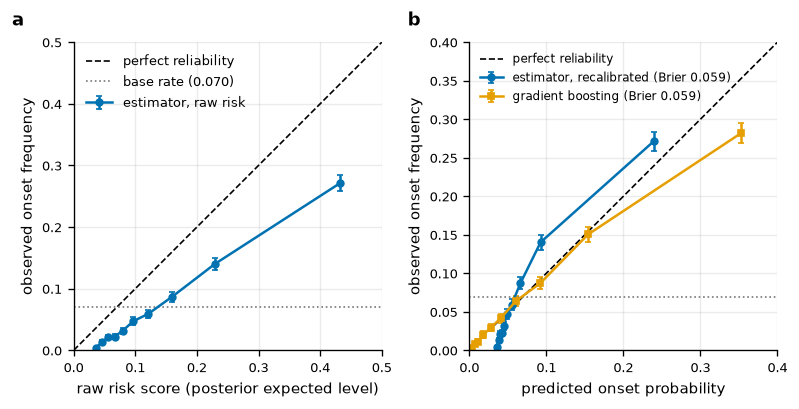

saved fig5_calibration


In [5]:
def rel(p,y,nb=10):
    b=pd.qcut(p,nb,duplicates="drop"); g=pd.DataFrame({"p":p,"y":y}).groupby(b,observed=True)
    m=g.y.mean().values; n=g.y.size().values; return g.p.mean().values,m,1.96*np.sqrt(m*(1-m)/n)
base=yte.mean(); fig,ax=plt.subplots(1,2,figsize=(W2,3.3))
xp,yp,e=rel(p_raw,yte); lim=0.5
ax[0].plot([0,lim],[0,lim],"k--",lw=1,label="perfect reliability"); ax[0].errorbar(xp,yp,yerr=e,fmt="-o",color=BLUE,ms=4,lw=1.5,capsize=2,label="estimator, raw risk")
ax[0].axhline(base,ls=":",color=GREY,lw=1,label=f"base rate ({base:.3f})"); ax[0].set_xlim(0,lim); ax[0].set_ylim(0,lim)
ax[0].set_xlabel("raw risk score (posterior expected level)"); ax[0].set_ylabel("observed onset frequency"); ax[0].legend(frameon=False,loc="upper left")
lim=float(np.ceil((max(rel(p_cal,yte)[0].max(),rel(p_gbm,yte)[0].max())+0.02)*20)/20); ax[1].plot([0,lim],[0,lim],"k--",lw=1,label="perfect reliability")
for p,c,m,lab in [(p_cal,BLUE,"o","estimator, recalibrated"),(p_gbm,ORANGE,"s","gradient boosting")]:
    xp,yp,e=rel(p,yte); ax[1].errorbar(xp,yp,yerr=e,fmt="-"+m,color=c,ms=4,lw=1.5,capsize=2,label=f"{lab} (Brier {brier(p,yte):.3f})")
ax[1].axhline(base,ls=":",color=GREY,lw=1); ax[1].set_xlim(0,lim); ax[1].set_ylim(0,lim)
ax[1].set_xlabel("predicted onset probability"); ax[1].set_ylabel("observed onset frequency"); ax[1].legend(frameon=False,loc="upper left",fontsize=7)
for a,s in zip(ax,"ab"): a.set_aspect("equal"); letter(a,s,x=-0.2)
plt.tight_layout(); save(fig,"fig5_calibration")


## Figure 6 - global attribution (all four signals)


signal  onset  non_onset  separation
    pm -0.574     -1.335       0.762
  wind -0.438     -0.548       0.110
   blh -0.344     -0.554       0.210
  temp -0.159     -0.421       0.262


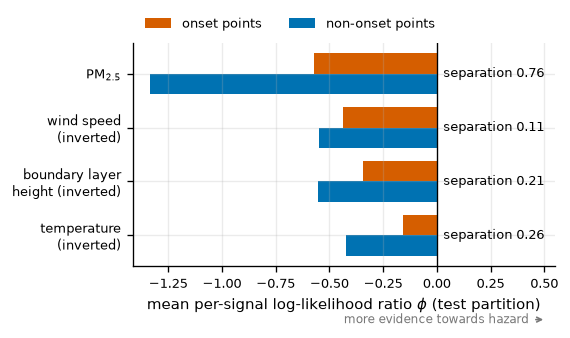

saved fig6_attribution


In [6]:
names={"pm":r"PM$_{2.5}$","wind":"wind speed\n(inverted)","blh":"boundary layer\nheight (inverted)","temp":"temperature\n(inverted)"}
on=te[te.label==1]; off=te[te.label==0]; A=[]
for s,_,_ in SIG: A.append(dict(signal=s,onset=on[f"phi_{s}"].mean(),non_onset=off[f"phi_{s}"].mean()))
A=pd.DataFrame(A); A["separation"]=A.onset-A.non_onset; print(A.round(3).to_string(index=False)); A.to_csv(OUT/"fig6_numbers.csv",index=False)
fig,ax=plt.subplots(figsize=(W2*0.72,3.0)); y=np.arange(len(A)); h=0.38
ax.barh(y-h/2,A.onset,h,color=VERM,label="onset points"); ax.barh(y+h/2,A.non_onset,h,color=BLUE,label="non-onset points")
ax.axvline(0,color="k",lw=.8); ax.set_yticks(y); ax.set_yticklabels([names[s] for s in A.signal]); ax.invert_yaxis()
xmin=min(A.onset.min(),A.non_onset.min())
for yi,r in zip(y,A.itertuples()): ax.text(0.03,yi,f"separation {r.separation:.2f}",va="center",ha="left",fontsize=7.5)
ax.set_xlim(xmin*1.06,0.55); ax.set_xlabel(r"mean per-signal log-likelihood ratio $\phi$ (test partition)")
ax.annotate("more evidence towards hazard",xy=(0.98,-0.24),xytext=(0.50,-0.24),xycoords="axes fraction",textcoords="axes fraction",fontsize=7,va="center",color=GREY,arrowprops=dict(arrowstyle="->",color=GREY))
ax.legend(frameon=False,loc="lower left",ncol=2,bbox_to_anchor=(0,1.0)); plt.tight_layout(); save(fig,"fig6_attribution")


## New figure - attribution for a single episode (worked example requested by Reviewer 2)


candidate onsets: 2301


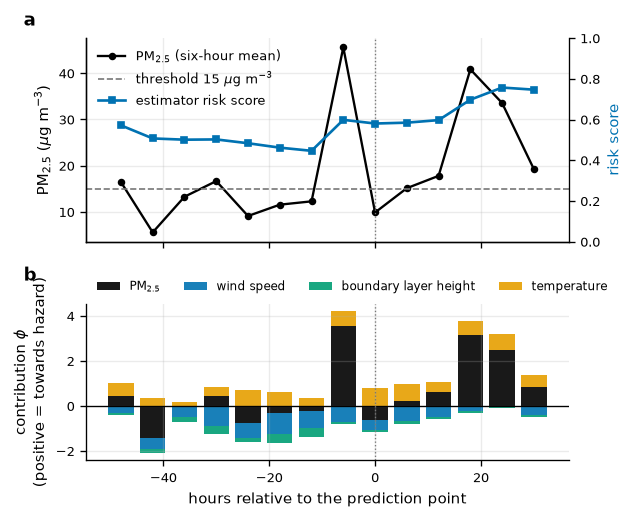

saved fig_attribution_case
episode: Oslo::Alnabru | prediction point 2019-01-18 00:00:00+00:00 | PM2.5 at the point 9.9, maximum in the next 24 h 40.8
         pm  wind   blh  temp
-18 h -0.34 -0.92 -0.41  0.60
-12 h -0.22 -0.75 -0.42  0.36
-6 h   3.57 -0.71 -0.11  0.65
0 h   -0.63 -0.46 -0.09  0.79


In [7]:
# selection rule (state it in the caption): among test onsets with a complete record around them and a peak below 60 ug m-3,
# take the one whose risk score is at the 90th percentile, i.e. a typical flagged case and not the most extreme one
cand=[]
for st,d in ST.items():
    v=d["v"]
    for t in range(10,len(v)-H-6):
        if d["tm"][t] or np.isnan(v[t-8:t+6]).any() or v[t]>=TAU: continue
        pk=np.max(v[t+1:t+1+H])
        if TAU<=pk<60: cand.append((d["risk"][t],st,t))
cand.sort(); _,st,t0=cand[int(0.9*len(cand))]; d=ST[st]; print("candidate onsets:",len(cand)); w0,w1=t0-8,t0+6; xs=np.arange(w0,w1); hrs=(xs-t0)*STEP
fig,ax=plt.subplots(2,1,figsize=(W2*0.8,4.4),sharex=True,gridspec_kw={"height_ratios":[1.3,1]})
ax[0].plot(hrs,d["v"][w0:w1],"-o",color="k",ms=3.5,lw=1.4,label=r"PM$_{2.5}$ (six-hour mean)"); ax[0].axhline(TAU,ls="--",color=GREY,lw=1,label=f"threshold {TAU:.0f} {UG}")
ax[0].axvline(0,color=GREY,lw=.8,ls=":"); ax[0].set_ylabel(f"PM$_{{2.5}}$ ({UG})")
a2=ax[0].twinx(); a2.plot(hrs,d["risk"][w0:w1],"-s",color=BLUE,ms=3.5,lw=1.6,label="estimator risk score"); a2.set_ylim(0,1); a2.set_ylabel("risk score",color=BLUE); a2.grid(False); a2.spines["right"].set_visible(True)
h1,l1=ax[0].get_legend_handles_labels(); h2,l2=a2.get_legend_handles_labels(); ax[0].legend(h1+h2,l1+l2,frameon=False,loc="upper left")
pos=np.zeros(len(xs)); neg=np.zeros(len(xs)); cc={"pm":"k","wind":BLUE,"blh":GREEN,"temp":ORANGE}; lab={"pm":r"PM$_{2.5}$","wind":"wind speed","blh":"boundary layer height","temp":"temperature"}
for s,_,_ in SIG:
    val=d["PHI"][s][w0:w1]; bot=np.where(val>=0,pos,neg); ax[1].bar(hrs,val,width=STEP*0.8,bottom=bot,color=cc[s],label=lab[s],alpha=.9)
    pos+=np.clip(val,0,None); neg+=np.clip(val,None,0)
ax[1].axhline(0,color="k",lw=.8); ax[1].axvline(0,color=GREY,lw=.8,ls=":"); ax[1].set_ylabel(r"contribution $\phi$"+"\n(positive = towards hazard)")
ax[1].set_xlabel("hours relative to the prediction point"); ax[1].legend(frameon=False,ncol=4,loc="lower left",bbox_to_anchor=(0,1.0),fontsize=7)
letter(ax[0],"a",x=-0.13); letter(ax[1],"b",x=-0.13,y=1.12); plt.tight_layout(); save(fig,"fig_attribution_case")
print("episode:",st,"| prediction point",d["idx"][t0],"| PM2.5 at the point %.1f, maximum in the next 24 h %.1f"%(d["v"][t0],np.nanmax(d["v"][t0+1:t0+1+H])))
print(pd.DataFrame({s:d["PHI"][s][t0-3:t0+1] for s,_,_ in SIG},index=[f"{h} h" for h in (-18,-12,-6,0)]).round(2).to_string())


## Figure 7 - hybrid against the gradient boosting model (from study5 CSV)


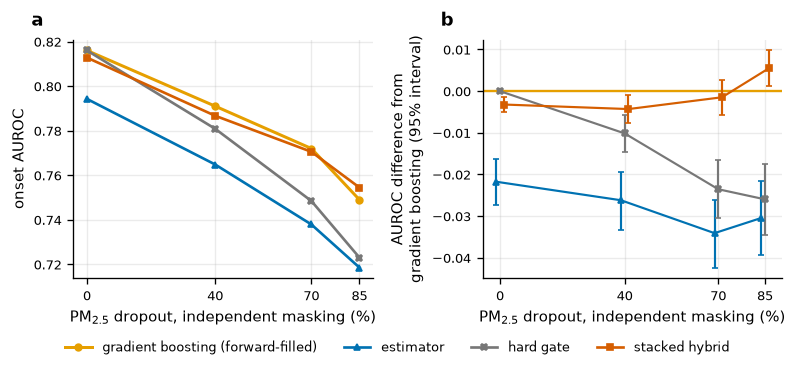

saved fig7_hybrid
 dropout    diff    lo95    hi95
    0.00 -0.0032 -0.0051 -0.0013
    0.40 -0.0043 -0.0076 -0.0010
    0.70 -0.0015 -0.0057  0.0026
    0.85  0.0055  0.0012  0.0098


In [8]:
P=pd.read_csv(O/"study5_rqc_hybrid/table3_paired_intervals.csv"); P["x"]=P.dropout*100
GBM={0.0:0.816,0.4:0.791,0.7:0.772,0.85:0.749}   # gradient boosting AUROC as printed in the manuscript table (study5)
st_={"monitor":(BLUE,"^","estimator"),"gate":(GREY,"X","hard gate"),"hybrid":(VERM,"s","stacked hybrid")}
fig,ax=plt.subplots(1,2,figsize=(W2,2.9)); xs=sorted(P.x.unique())
ax[0].plot(xs,[GBM[k/100] for k in xs],"-o",color=ORANGE,lw=1.8,ms=4,label="gradient boosting (forward-filled)")
ax[1].axhline(0,color=ORANGE,lw=1.4,label="gradient boosting (reference)")
for i,(mname,(c,m,lab)) in enumerate(st_.items()):
    g=P[P.model==mname].sort_values("x"); off=(i-1)*1.2
    ax[0].plot(g.x,[GBM[k] for k in g.dropout]+g["diff"].values,"-"+m,color=c,lw=1.6,ms=4,label=lab)
    ax[1].errorbar(g.x+off,g["diff"],yerr=[g["diff"]-g.lo95,g.hi95-g["diff"]],fmt="-"+m,color=c,lw=1.3,ms=4,capsize=2,label=lab)
ax[0].set_ylabel("onset AUROC")
ax[1].set_ylabel("AUROC difference from\ngradient boosting (95% interval)")
h_,l_=ax[0].get_legend_handles_labels(); fig.legend(h_,l_,frameon=False,loc="lower center",ncol=4,bbox_to_anchor=(0.5,-0.07))
for a,s in zip(ax,"ab"): a.set_xticks(xs); a.set_xlabel(r"PM$_{2.5}$ dropout, independent masking (%)"); letter(a,s)
plt.tight_layout(); save(fig,"fig7_hybrid")
print(P[P.model=="hybrid"][["dropout","diff","lo95","hi95"]].round(4).to_string(index=False))


## New figure - newly commissioned station (from study21 CSV)


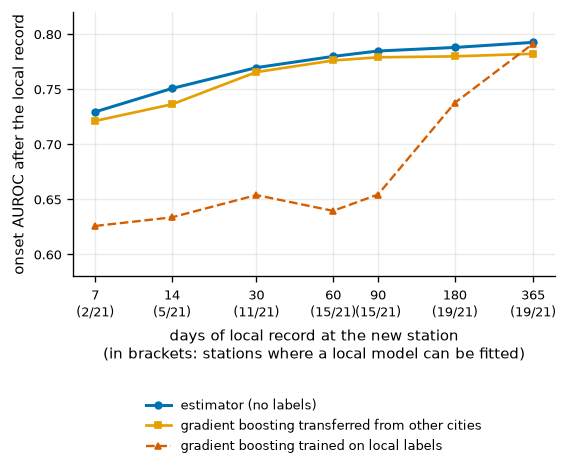

saved fig_new_station


In [9]:
R=pd.read_csv(O/"study21_new_station/s21_new_station.csv")
fig,ax=plt.subplots(figsize=(W2*0.72,3.2))
ax.plot(R.days,R.est,"-o",color=BLUE,lw=1.8,ms=4,label="estimator (no labels)")
ax.plot(R.days,R.loco_gbm,"-s",color=ORANGE,lw=1.6,ms=4,label="gradient boosting transferred from other cities")
ax.plot(R.days,R.local_gbm,"--^",color=VERM,lw=1.4,ms=4,label="gradient boosting trained on local labels")
ax.set_xscale("log"); ax.set_xticks(R.days); ax.set_xticklabels([f"{d_}\n({s_})" for d_,s_ in zip(R.days,R.local_st)]); ax.minorticks_off()
ax.set_xlabel("days of local record at the new station\n(in brackets: stations where a local model can be fitted)"); ax.set_ylabel("onset AUROC after the local record"); ax.set_ylim(0.58,0.82)
fig.legend(frameon=False,loc="lower center",ncol=1,bbox_to_anchor=(0.55,-0.22),fontsize=7.5); plt.tight_layout(); save(fig,"fig_new_station")


## New figure - sensitivity to modality weights and weather-transition coefficients (from study14 and study17 CSVs)


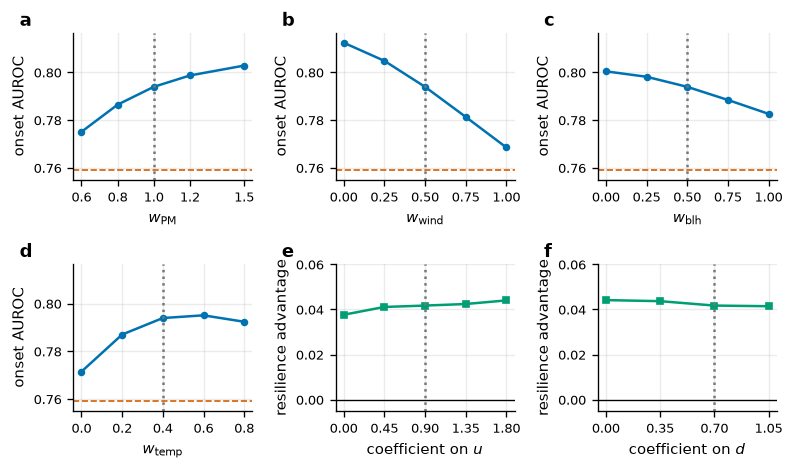

saved fig_sensitivity_weights


In [10]:
Wt=pd.read_csv(O/"study14_weights/b6_modality_weight_sweep.csv"); Rz=pd.read_csv(O/"study17_weathercoef/s17_resilience.csv"); Rz=Rz[Rz.dropout==0.85]
spec={"wpm":1.0,"ww":0.5,"wb":0.5,"wt":0.4}; nm={"wpm":r"$w_{\mathrm{PM}}$","ww":r"$w_{\mathrm{wind}}$","wb":r"$w_{\mathrm{blh}}$","wt":r"$w_{\mathrm{temp}}$"}
fig,ax=plt.subplots(2,3,figsize=(W2,4.0)); ax=ax.ravel(); lo,hi=Wt.auroc.min()-.004,Wt.auroc.max()+.004
for a,k in zip(ax[:4],["wpm","ww","wb","wt"]):
    g=Wt[Wt.param==k]; a.plot(g.value,g.auroc,"-o",color=BLUE,ms=3.5,lw=1.5); a.axvline(spec[k],ls=":",color=GREY); a.axhline(0.759,ls="--",color=VERM,lw=1)
    a.set_ylim(min(lo,0.755),hi); a.set_xlabel(nm[k]); a.set_xticks(g.value); a.set_ylabel("onset AUROC")
for a,k,xl,sp in [(ax[4],"c_up","coefficient on $u$",0.9),(ax[5],"c_dn","coefficient on $d$",0.7)]:
    g=Rz[Rz.sweep==k]; a.plot(g[k],g.advantage,"-s",color=GREEN,ms=3.5,lw=1.5); a.axvline(sp,ls=":",color=GREY); a.axhline(0,color="k",lw=.8); a.set_ylim(-0.005,0.06); a.set_xlabel(xl); a.set_xticks(g[k]); a.set_ylabel("resilience advantage")
for a,s in zip(ax,"abcdef"): letter(a,s,x=-0.3,y=1.02)
plt.tight_layout(); save(fig,"fig_sensitivity_weights")


## New figure - Beijing benchmark (from study24 CSV)

study18 used the configuration of the initial feasibility study; study24 uses the configuration described in the Methods, so the figure is drawn from study24.

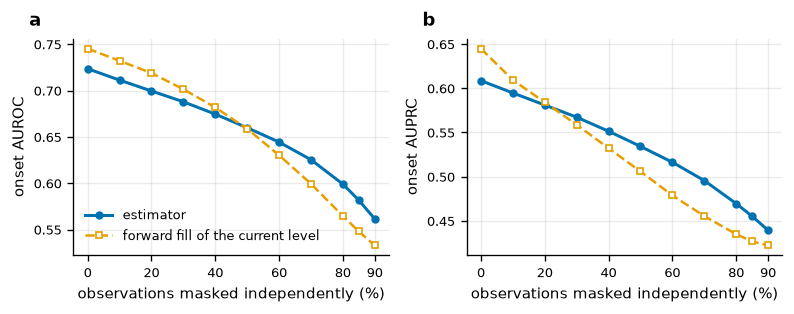

saved fig_beijing


In [11]:
B=pd.read_csv(O/"study24_beijing_aligned/s24_beijing_dropout.csv"); x=B.dropout*100
fig,ax=plt.subplots(1,2,figsize=(W2,2.7))
for a,m,s in zip(ax,["AUROC","AUPRC"],"ab"):
    a.plot(x,B[f"est_{m}"],"-o",color=BLUE,lw=1.8,ms=4,label="estimator"); a.plot(x,B[f"LOCF_{m}"],"--s",color=ORANGE,lw=1.5,ms=4,mfc="white",label="forward fill of the current level")
    a.set_xlabel(r"PM$_{2.5}$ masked independently (%)"); a.set_ylabel(f"onset {m}"); a.set_xticks([0,20,40,60,80,90]); letter(a,s)
ax[0].legend(frameon=False,loc="lower left"); plt.tight_layout(); save(fig,"fig_beijing")
